In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.feature_extraction.text import CountVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

import joblib

In [2]:
df = pd.read_csv("../data/phishing_site_urls.csv")

In [3]:
df.head()

,URL,Label
0,nobell.it/70ffb52d079109dca5664cce6f317373782/...,bad
1,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...,bad
2,serviciosbys.com/paypal.cgi.bin.get-into.herf....,bad
3,mail.printakid.com/www.online.americanexpress....,bad
4,thewhiskeydregs.com/wp-content/themes/widescre...,bad


In [4]:
df.shape

(549346, 2)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 549346 entries, 0 to 549345
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   URL     549346 non-null  object
 1   Label   549346 non-null  object
dtypes: object(2)
memory usage: 8.4+ MB


In [6]:
df.isnull().sum()

URL      0
Label    0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(42150)

In [8]:
df.drop_duplicates(inplace=True)

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df['Label'].unique()

array(['bad', 'good'], dtype=object)

In [11]:
df['Label']=df['Label'].map({
    'good':0,
    'bad':1
})

In [12]:
df.head()

,URL,Label
0,nobell.it/70ffb52d079109dca5664cce6f317373782/...,1
1,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...,1
2,serviciosbys.com/paypal.cgi.bin.get-into.herf....,1
3,mail.printakid.com/www.online.americanexpress....,1
4,thewhiskeydregs.com/wp-content/themes/widescre...,1


In [13]:
df['URL_Length'] = df['URL'].apply(len)
df['Dots'] = df['URL'].str.count(r'\.')
df['Hyphens'] = df['URL'].str.count('-')
df['Digits'] = df['URL'].str.count(r'\d')
df['Slashes'] = df['URL'].str.count('/')
df['HTTPS'] = df['URL'].str.contains('https').astype(int)
df['IP_Address'] = df['URL'].str.contains(
    r'\b(?:\d{1,3}\.){3}\d{1,3}\b',
    regex=True
).astype(int)
df['Special_Chars'] = df['URL'].str.count(r'[@?=&_%]')

In [14]:
df.head()

,URL,Label,URL_Length,Dots,Hyphens,Digits,Slashes,HTTPS,IP_Address,Special_Chars
0,nobell.it/70ffb52d079109dca5664cce6f317373782/...,1,225,6,4,58,10,0,0,12
1,www.dghjdgf.com/paypal.co.uk/cycgi-bin/webscrc...,1,81,5,2,1,4,0,0,4
2,serviciosbys.com/paypal.cgi.bin.get-into.herf....,1,177,7,1,47,11,0,0,0
3,mail.printakid.com/www.online.americanexpress....,1,60,6,0,0,2,0,0,0
4,thewhiskeydregs.com/wp-content/themes/widescre...,1,116,1,1,21,10,0,0,1


In [15]:
features=[
'Label',
'URL_Length',
'Dots',
'Hyphens',
'Digits',
'Slashes',
'HTTPS',
'IP_Address',
'Special_Chars'
]

corr=df[features].corr()

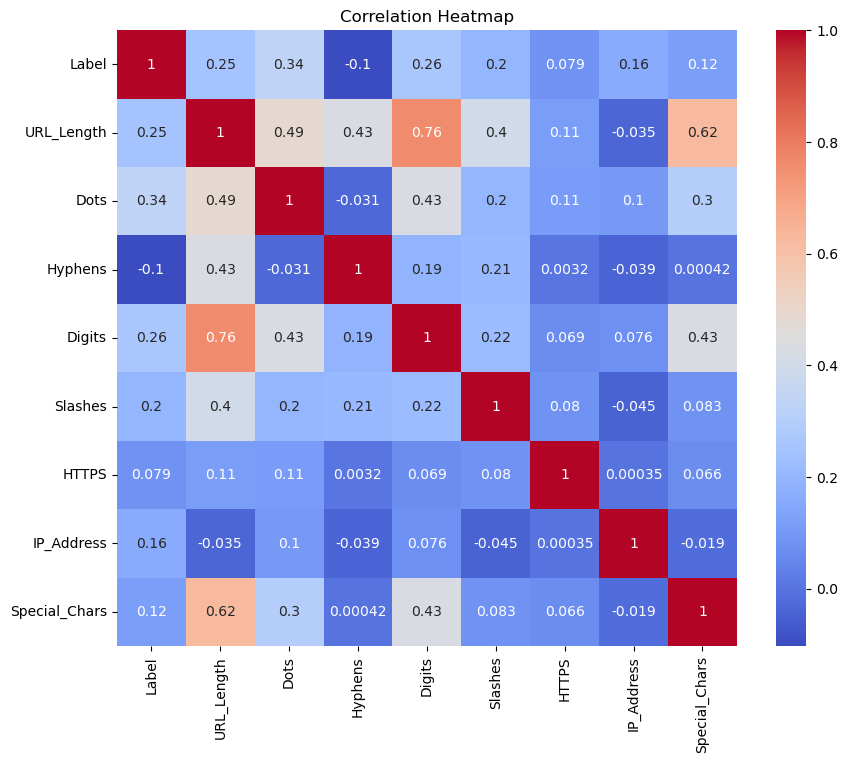

In [16]:
plt.figure(figsize=(10,8))

sns.heatmap(corr,
            annot=True,
            cmap='coolwarm')

plt.title("Correlation Heatmap")

plt.show()

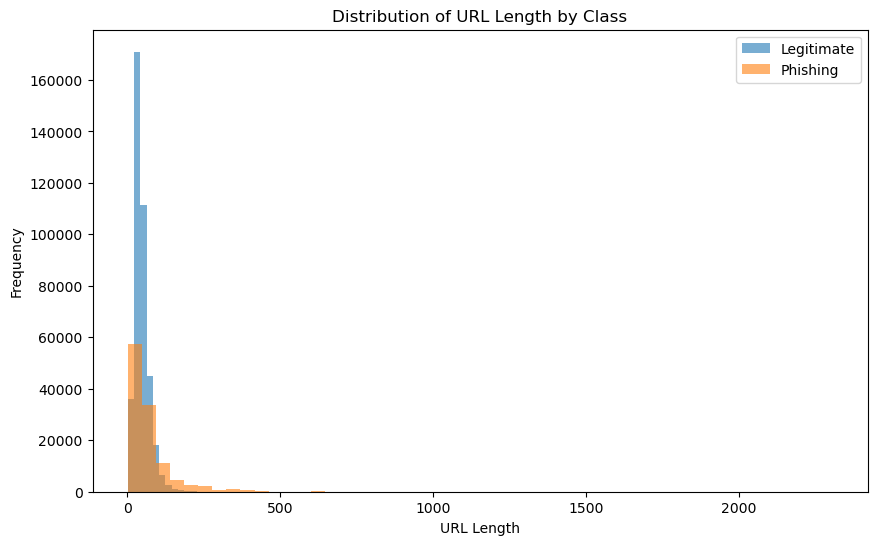

In [17]:
plt.figure(figsize=(10,6))

plt.hist(df[df['Label']==0]['URL_Length'],
         bins=50,
         alpha=0.6,
         label='Legitimate')

plt.hist(df[df['Label']==1]['URL_Length'],
         bins=50,
         alpha=0.6,
         label='Phishing')

plt.xlabel("URL Length")
plt.ylabel("Frequency")
plt.title("Distribution of URL Length by Class")
plt.legend()

plt.show()

In [18]:
X=df['URL']

y=df['Label']

In [19]:
X_train,X_test,y_train,y_test=train_test_split(
X,
y,
test_size=0.2,
random_state=42,
stratify=y
)

In [20]:
vectorizer=CountVectorizer(
analyzer='char',
ngram_range=(2,5),
max_features=100000
)

In [21]:
X_train_vec=vectorizer.fit_transform(X_train)

X_test_vec=vectorizer.transform(X_test)

In [22]:
print(X_train_vec.shape)

print(X_test_vec.shape)

(405756, 100000)
(101440, 100000)


In [23]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Multinomial Naive Bayes": MultinomialNB(),
    "Linear SVM": LinearSVC()
}

In [24]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []

for name, model in models.items():
    model.fit(X_train_vec, y_train)

    y_pred = model.predict(X_test_vec)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred)
    })

In [25]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
)

results_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.979978,0.966662,0.943701,0.955043
2,Linear SVM,0.976774,0.952347,0.944182,0.948247
1,Multinomial Naive Bayes,0.949310,0.912008,0.857830,0.884090


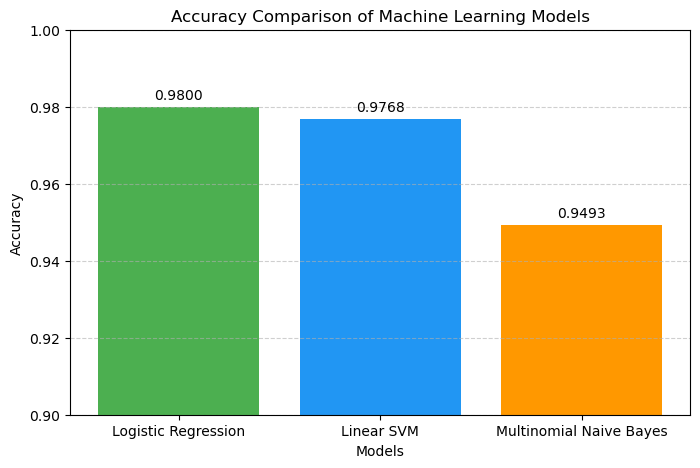

In [26]:
plt.figure(figsize=(8,5))

colors = ['#4CAF50', '#2196F3', '#FF9800']

bars = plt.bar(results_df["Model"], results_df["Accuracy"], color=colors)

plt.title("Accuracy Comparison of Machine Learning Models")
plt.xlabel("Models")
plt.ylabel("Accuracy")
plt.ylim(0.90, 1.00)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2,
             height + 0.002,
             f"{height:.4f}",
             ha='center')

plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.show()

In [27]:
best_model_name = results_df.loc[results_df["Accuracy"].idxmax(), "Model"]

print("Best Model:", best_model_name)

Best Model: Logistic Regression


In [28]:
best_model = models[best_model_name]

In [29]:
y_pred = best_model.predict(X_test_vec)

In [30]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.98      0.99      0.99     78580
           1       0.97      0.94      0.96     22860

    accuracy                           0.98    101440
   macro avg       0.98      0.97      0.97    101440
weighted avg       0.98      0.98      0.98    101440



In [31]:
cm = confusion_matrix(y_test, y_pred)

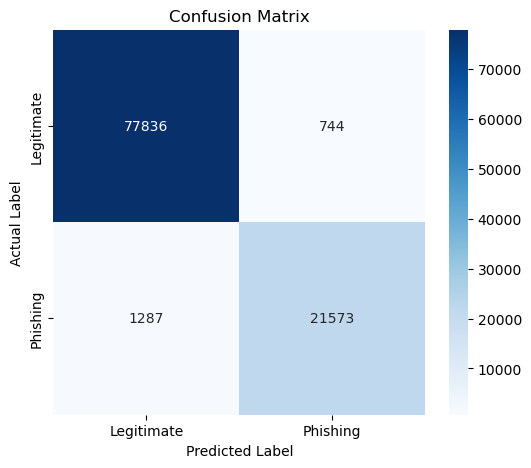

In [32]:
plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Phishing"],
    yticklabels=["Legitimate", "Phishing"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")

plt.show()

In [33]:
joblib.dump(best_model, "phishing_model.pkl")

['phishing_model.pkl']

In [34]:
joblib.dump(vectorizer, "vectorizer.pkl")

['vectorizer.pkl']

In [35]:
from pathlib import Path

for file in Path(".").glob("*.pkl"):
    print(file)

phishing_model.pkl
vectorizer.pkl


In [36]:
import joblib

model = joblib.load("../models/phishing_model.pkl")
vectorizer = joblib.load("../models/vectorizer.pkl")

test_urls = [
    "https://www.google.com",
    "https://www.amazon.in",
    "https://www.github.com"
]

for url in test_urls:
    vec = vectorizer.transform([url])
    pred = model.predict(vec)[0]
    print(url, "->", pred)

C:\Users\mrg72\AppData\Roaming\Python\Python313\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.7.2 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


https://www.google.com -> 1
https://www.amazon.in -> 1
https://www.github.com -> 1


C:\Users\mrg72\AppData\Roaming\Python\Python313\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator CountVectorizer from version 1.7.2 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [37]:
test_urls = [
    "https://www.google.com",
    "https://www.amazon.in",
    "https://www.github.com"
]

for url in test_urls:
    vec = vectorizer.transform([url])   # Use the vectorizer already in memory
    pred = best_model.predict(vec)[0]   # Use the trained model already in memory
    print(url, "->", pred)

https://www.google.com -> 1
https://www.amazon.in -> 1
https://www.github.com -> 1


In [38]:
test_urls = [
    "google.com",
    "www.google.com",
    "amazon.in",
    "www.amazon.in",
    "github.com",
    "www.github.com"
]

for url in test_urls:
    vec = vectorizer.transform([url])
    pred = model.predict(vec)[0]
    print(url, "->", pred)

google.com -> 1
www.google.com -> 1
amazon.in -> 0
www.amazon.in -> 0
github.com -> 1
www.github.com -> 1


In [39]:
df[df["Label"] == 0].sample(10)

,URL,Label,URL_Length,Dots,Hyphens,Digits,Slashes,HTTPS,IP_Address,Special_Chars
146229,atelier-s.org/about_us,0,22,1,1,0,1,0,0,1
343387,fullbooks.com/A-School-History-of-the-United-S...,0,57,2,6,1,1,0,0,0
54912,www.nanomag.co.kr/eng/,0,22,3,0,0,2,0,0,0
145081,articles.latimes.com/2000/jan/29/news/mn-58903,0,46,2,1,11,5,0,0,0
446600,thetasteofgermany.com/,0,22,1,0,0,1,0,0,0
336865,fighters.com/11/15/miguel-torres-ready-to-re-i...,0,75,1,9,4,3,0,0,0
193493,geology.com/state-map/south-carolina.shtml,0,42,2,2,0,2,0,0,0
58157,math.unm.edu/ACA/2001/2001.html,0,31,3,0,8,3,0,0,0
299449,carionltd.com/doc.php?st=tx&cy=bellaire&pn=sta...,0,72,2,2,6,1,0,0,8
219303,n4g.com/news/831410/deus-ex-human-revolutions-...,0,113,1,13,7,4,0,0,0


In [40]:
print(df["Label"].value_counts())

Label
0    392897
1    114299
Name: count, dtype: int64


In [41]:
print(df[df["URL"].str.contains("google", case=False, na=False)][["URL", "Label"]].head(20))

                                                    URL  Label
11    docs.google.com/spreadsheet/viewform?formkey=d...      1
36    docs.google.com/a/unmsm.edu.pe/spreadsheet/vie...      1
51    docs.google.com/spreadsheet/viewform?formkey=d...      1
86    docs.google.com/a/airtelmail.in/spreadsheet/vi...      1
107   docs.google.com/spreadsheet/viewform?formkey=d...      1
177   docs.google.com/spreadsheet/viewform?formkey=d...      1
289   docs.google.com/spreadsheet/viewform?formkey=d...      1
297   'www.google.ad/url?sa=f&rct=j&url=https:/www.p...      1
458   docs.google.com/spreadsheet/viewform?formkey=d...      1
460   docs.google.com/a/poli.ufrj.br/spreadsheet/vie...      1
523   docs.google.com/a/uic.edu/spreadsheet/viewform...      1
1251  docs.google.com/spreadsheet/viewform?formkey=d...      1
1269  docs.google.com/a/sau.edu/spreadsheet/viewform...      1
1308  www.google.com.au/url?sa=t&amp;rct=j&amp;q=sit...      1
1325  'www.google.com.au/url?sa=t&amp;rct=j&amp;q=si...

In [42]:
print(df[df["URL"].str.contains("github", case=False, na=False)][["URL", "Label"]].head(20))

                                            URL  Label
58690           thinkaurelius.github.com/titan/      0
61925                   github.com/ctm/executor      0
69289                github.com/JoKnopp/dmoz2db      0
70664  github.com/myronmarston/fractal_composer      0
71985    github.com/sawilde/partcover.net4/wiki      0
72539                    github.com/ReactorORM/      0
76215               github.com/joyent/node/wiki      0
76217     visionmedia.github.com/masteringnode/      0
76221                   maritz.github.com/nohm/      0
76222    tautologistics.github.com/nodemachine/      0
76224            learnboost.github.com/cluster/      0
76229             olegp.github.com/common-node/      0
76230              visionmedia.github.com/keys/      0
76231       tuxychandru.github.com/grasshopper/      0
76232            idmillington.github.com/rowan/      0
76233                   pgte.github.com/alfred/      0
78345            github.com/edgecase/ruby_koans      0
79928     

In [43]:
print(df[df["URL"].str.contains("amazon", case=False, na=False)][["URL", "Label"]].head(20))

                                                     URL  Label
1234                             amazon.de-register.net/      1
1997   e-2dj6wjloskczkeo.stats.esomniture.com/b/ss/e-...      1
2080   www.michaeln.org/www.amazon.com/?user=enIxaW5j...      1
4851                 supportservice-amazon.de/verifi.htm      1
4852                supportservice-amazon.com/verifi.htm      1
5297       s3-sa-east-1.amazonaws.com/livemsn/Entrar.htm      1
5463   bancaribe-ve-lb-1328493527.us-east-1.elb.amazo...      1
6049               angleich-amazonaccount.net/verifi.htm      1
7992                          kunde.supported-amazon.net      1
7993                               supported-amazon.net/      1
10094  www.lucky-bamboo-plants.info/amazon/Enter.php?...      1
10868  'e-2dj6wjloskczkeo.stats.esomniture.com/b/ss/e...      1
11027  www.amsca.co.uk/amazon/labels/us/details.html?...      1
12153  ec2-54-245-18-172.us-west-2.compute.amazonaws....      1
13914  ebay.bestmat.ch.s3-website-us-eas